# Machine Learning Classification Project: Heart Disease Prediction

## Problem Statement
Predict the presence or absence of heart disease based on various clinical and demographic features. This exercise will cover the complete machine learning pipeline from data preprocessing to model evaluation.

## Dataset
The dataset contains 918 instances with 11 clinical features and 1 target variable:

**Features:**
1. Age: Age of the patient (years)
2. Sex: Gender of the patient (M: Male, F: Female)
3. ChestPainType: Type of chest pain (TA: Typical Angina, ATA: Atypical Angina, NAP: Non-Anginal Pain, ASY: Asymptomatic)
4. RestingBP: Resting blood pressure (mm Hg)
5. Cholesterol: Serum cholesterol (mg/dl)
6. FastingBS: Fasting blood sugar (1: if FastingBS > 120 mg/dl, 0: otherwise)
7. RestingECG: Resting electrocardiogram results (Normal, ST, LVH)
8. MaxHR: Maximum heart rate achieved
9. ExerciseAngina: Exercise-induced angina (Y: Yes, N: No)
10. Oldpeak: Oldpeak = ST depression induced by exercise relative to rest
11. ST_Slope: Slope of the peak exercise ST segment (Up, Flat, Down)

**Target:**
12. HeartDisease: Presence of heart disease (1: yes, 0: no)

## Task 1: Data Loading and Initial Exploration
- Load the dataset
- Display basic information (shape, data types, null values)
- Generate descriptive statistics
- Check for class distribution (target variable)

In [2]:
# Your code here
# ============================================================
# IMPORTS AND SETUP
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV,
    StratifiedKFold, learning_curve
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, auc, ConfusionMatrixDisplay, RocCurveDisplay
)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
np.random.seed(42)

print("✅ All libraries loaded.")

# ============================================================
# TASK 1 — DATA LOADING AND INITIAL EXPLORATION
# ============================================================
df = pd.read_csv("heart.csv")
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]   # safety

print("=" * 60)
print("SHAPE:", df.shape)
print("=" * 60)

print("\n📋 First 5 rows:")
print(df.head())

print("\n📋 Data types:")
print(df.dtypes)

print("\n📋 Missing values per column:")
print(df.isnull().sum())

print("\n📋 Descriptive statistics:")
print(df.describe().T)

print("\n🎯 Target distribution:")
print(df["target"].value_counts())
print(f"\nHeart disease rate: {df['target'].mean():.4f}")

ModuleNotFoundError: No module named 'numpy'

## Task 2: Data Preprocessing
- Handle missing values (if any)
- Encode categorical variables (Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope)
- Scale/normalize numerical features
- Check for class imbalance
- Split data into features (X) and target (y)

In [3]:
# Your code here
# ============================================================
# TASK 2 — DATA PREPROCESSING
# ============================================================
# NOTE: This version of the dataset (from Kaggle "Heart Failure Prediction")
# already has numerical encodings for all categorical variables.
# We'll rename columns for readability and verify encodings.

# Quick sanity check: identify discrete vs continuous columns
for col in df.columns:
    n_unique = df[col].nunique()
    print(f"{col:<12} | dtype={str(df[col].dtype):<8} | unique={n_unique}")

# ---- Verify categorical encodings (if they appear as strings, encode them) ----
categorical_cols = []
for col in df.columns:
    if df[col].dtype == "object":
        categorical_cols.append(col)

print(f"\nObject (string) columns: {categorical_cols}")

# If your CSV has string labels like "M/F", "TA/ATA/...", encode them:
le_dict = {}
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    le_dict[col] = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"Encoded {col}: {le_dict[col]}")

# ---- Split features and target ----
X = df.drop(columns=["target"]).values
y = df["target"].values

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")

# ---- Class balance check ----
print(f"\nClass balance: {np.bincount(y)}")
print(f"Ratio: {np.bincount(y)[0]} / {np.bincount(y)[1]} = "
      f"{np.bincount(y)[0]/np.bincount(y)[1]:.3f}")
print("→ Reasonably balanced (no SMOTE needed)")

age          | dtype=int64    | unique=41
sex          | dtype=int64    | unique=2
cp           | dtype=int64    | unique=4
trestbps     | dtype=int64    | unique=49
chol         | dtype=int64    | unique=152
fbs          | dtype=int64    | unique=2
restecg      | dtype=int64    | unique=3
thalach      | dtype=int64    | unique=91
exang        | dtype=int64    | unique=2
oldpeak      | dtype=float64  | unique=40
slope        | dtype=int64    | unique=3
ca           | dtype=int64    | unique=5
thal         | dtype=int64    | unique=4
target       | dtype=int64    | unique=2

Object (string) columns: []

X shape: (1025, 13)
y shape: (1025,)

Class balance: [499 526]
Ratio: 499 / 526 = 0.949
→ Reasonably balanced (no SMOTE needed)


## Task 3: Exploratory Data Analysis (EDA)
- Plot correlation matrix heatmap
- Create distribution plots for numerical features
- Visualize relationships between features and target
- Create pairplots for selected features

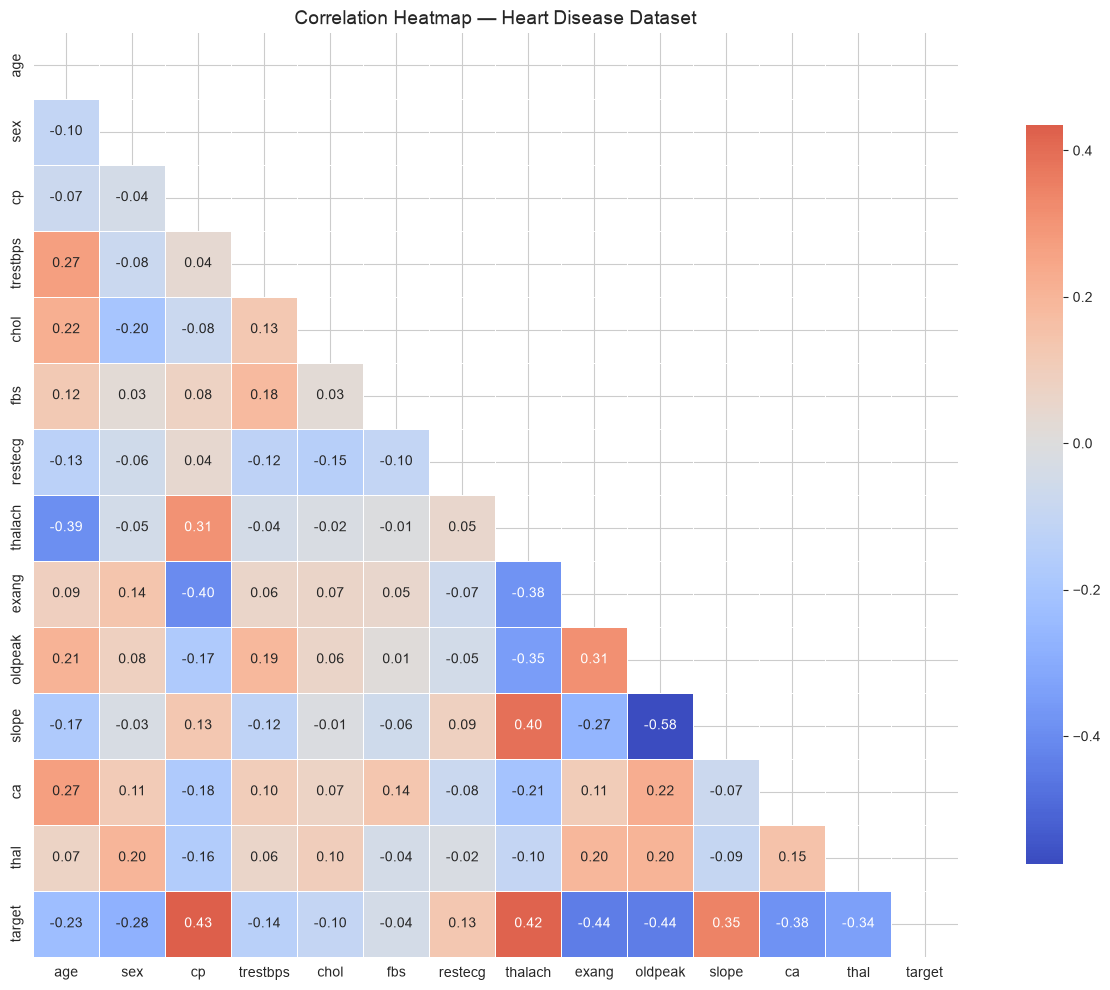

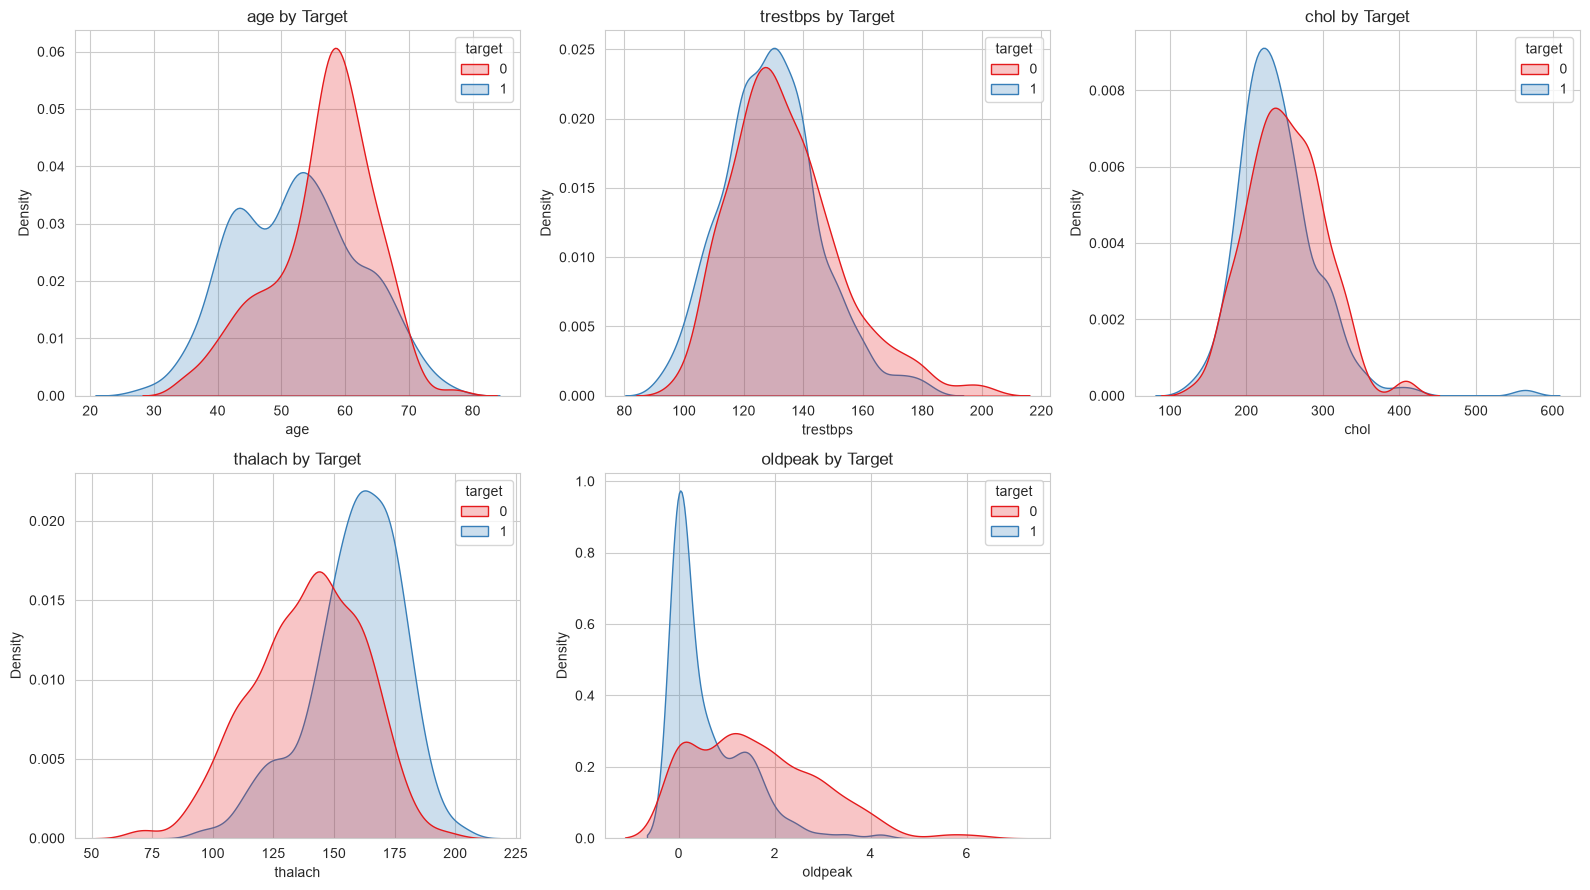

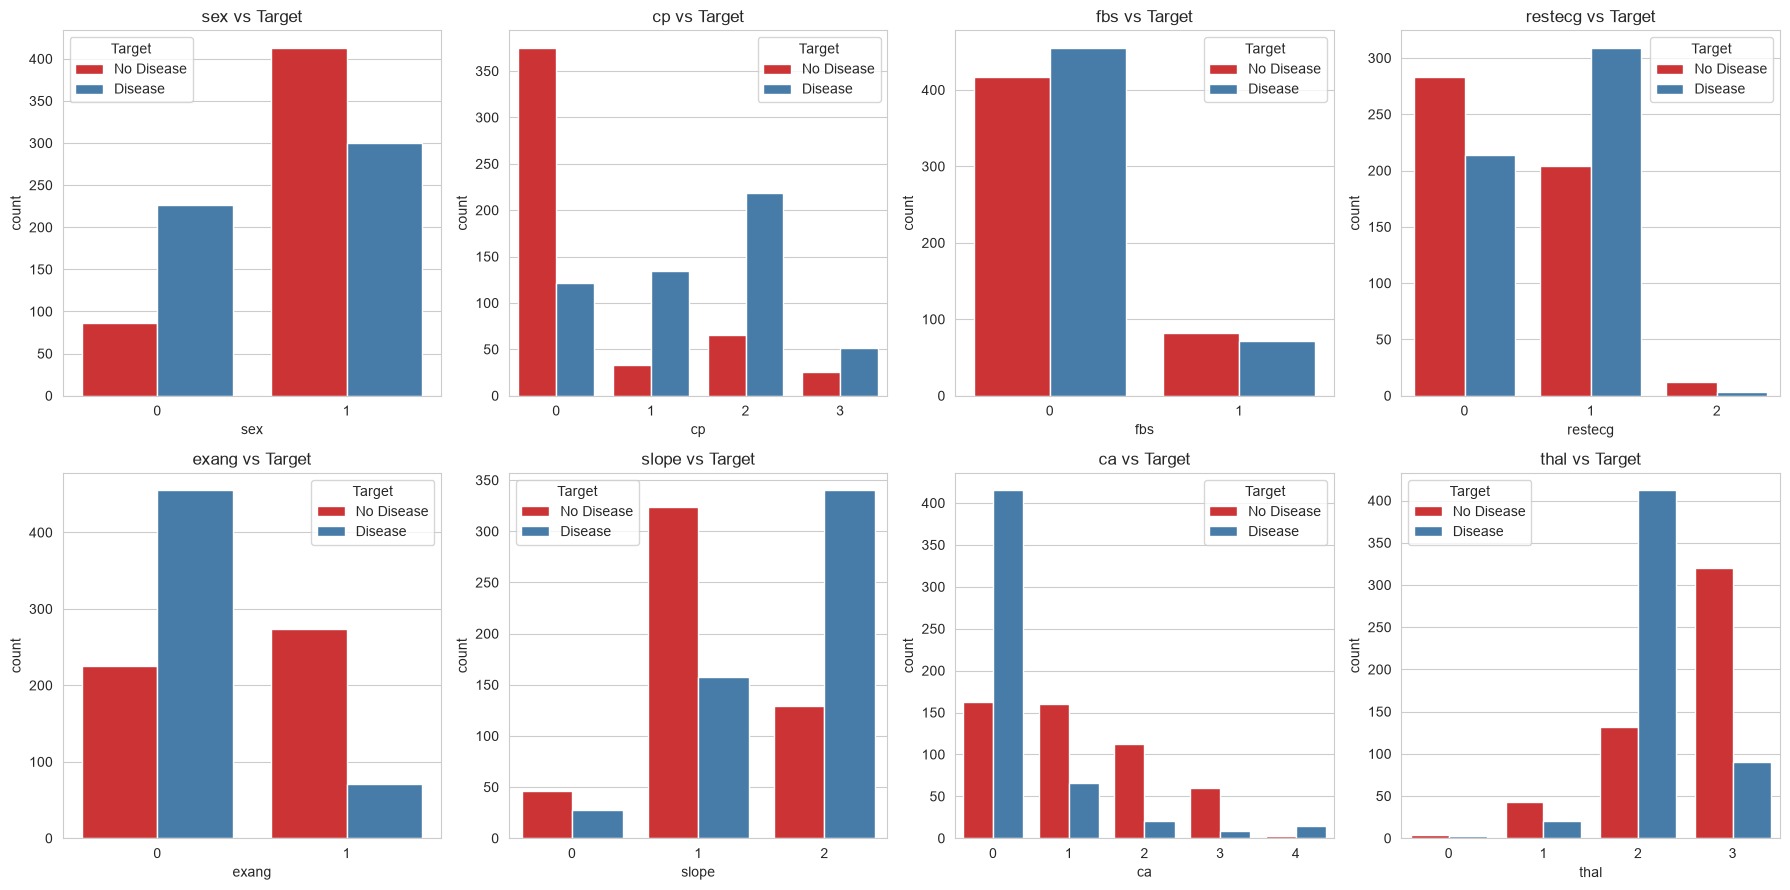

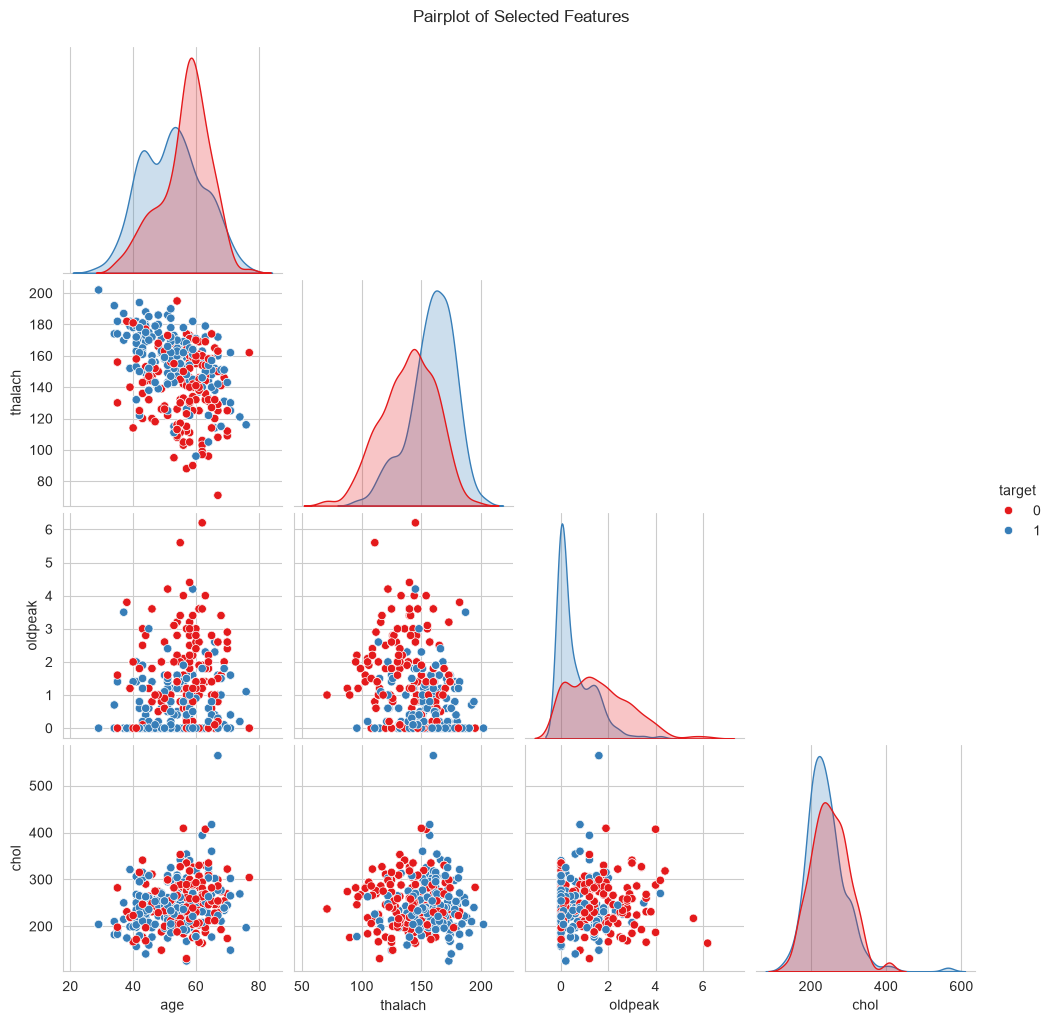

In [4]:
# Your code here
# ============================================================
# TASK 3 — EDA
# ============================================================
# ---- 3.1 Correlation heatmap ----
plt.figure(figsize=(14, 10))
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap — Heart Disease Dataset", fontsize=14)
plt.tight_layout()
plt.show()

# ---- 3.2 Distribution of numerical features by target ----
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.kdeplot(data=df, x=col, hue="target",
                fill=True, common_norm=False, palette="Set1", ax=ax)
    ax.set_title(f"{col} by Target")
    ax.set_xlabel(col)

axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

# ---- 3.3 Categorical features vs target ----
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df, x=col, hue="target", palette="Set1", ax=ax)
    ax.set_title(f"{col} vs Target")
    ax.legend(title="Target", labels=["No Disease", "Disease"])
plt.tight_layout()
plt.show()

# ---- 3.4 Pairplot on selected features ----
selected = ["age", "thalach", "oldpeak", "chol", "target"]
sns.pairplot(df[selected], hue="target", palette="Set1", corner=True)
plt.suptitle("Pairplot of Selected Features", y=1.02)
plt.show()

## Task 4: Data Splitting and Cross-Validation Setup
- Split data into training (80%) and testing (20%) sets
- Implement K-Fold cross-validation (k=5 or k=10)
- Explain the purpose of cross-validation in reducing overfitting

In [5]:
# Your code here
# ============================================================
# TASK 4 — DATA SPLIT AND CROSS-VALIDATION SETUP
# ============================================================
# ---- 4.1 80/20 split ----
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train class balance: {np.bincount(y_train)}")
print(f"Test class balance:  {np.bincount(y_test)}")

# ---- 4.2 Feature scaling (for KNN, LogReg, SVM) ----
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ---- 4.3 Stratified K-Fold CV ----
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\n✅ StratifiedKFold with k=5 ready.")
print("✅ Feature scaling done (mean≈0, std≈1 on train).")

Train: (820, 13), Test: (205, 13)
Train class balance: [399 421]
Test class balance:  [100 105]

✅ StratifiedKFold with k=5 ready.
✅ Feature scaling done (mean≈0, std≈1 on train).


## Task 5: Model Implementation and Training
Implement and compare the following algorithms:
1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree Classifier
4. Random Forest Classifier
5. Support Vector Machine (SVM)

For each algorithm:
- Initialize the model with appropriate parameters
- Train using cross-validation
- Perform hyperparameter tuning

### 5.1 K-Nearest Neighbors (KNN)

In [6]:
# Your code here
# ============================================================
# TASK 5.1 — K-NEAREST NEIGHBORS
# ============================================================
knn_params = {"n_neighbors": [3, 5, 7, 9, 11, 15, 21],
              "weights": ["uniform", "distance"]}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_params,
    cv=cv, scoring="f1", n_jobs=-1
)
knn_grid.fit(X_train_scaled, y_train)

print("KNN best params:", knn_grid.best_params_)
print(f"KNN best CV F1:  {knn_grid.best_score_:.4f}")

best_knn = knn_grid.best_estimator_

KNN best params: {'n_neighbors': 21, 'weights': 'distance'}
KNN best CV F1:  0.9858


### 5.2 Logistic Regression

In [7]:
# Your code here
# ============================================================
# TASK 5.2 — LOGISTIC REGRESSION
# ============================================================
lr_params = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l2"],
    "solver": ["lbfgs", "liblinear"],
    "class_weight": [None, "balanced"]
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    lr_params,
    cv=cv, scoring="f1", n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

print("LogReg best params:", lr_grid.best_params_)
print(f"LogReg best CV F1:  {lr_grid.best_score_:.4f}")

best_lr = lr_grid.best_estimator_

LogReg best params: {'C': 10, 'class_weight': None, 'penalty': 'l2', 'solver': 'lbfgs'}
LogReg best CV F1:  0.8560


### 5.3 Decision Tree Classifier

In [8]:
# Your code here
# ============================================================
# TASK 5.3 — DECISION TREE
# ============================================================
dt_params = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6, 8, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    cv=cv, scoring="f1", n_jobs=-1
)
dt_grid.fit(X_train, y_train)   # no scaling needed

print("DT best params:", dt_grid.best_params_)
print(f"DT best CV F1:  {dt_grid.best_score_:.4f}")

best_dt = dt_grid.best_estimator_

DT best params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
DT best CV F1:  0.9856


### 5.4 Random Forest Classifier

In [9]:
# Your code here
# ============================================================
# TASK 5.4 — RANDOM FOREST
# ============================================================
rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=cv, scoring="f1", n_jobs=-1
)
rf_grid.fit(X_train, y_train)

print("RF best params:", rf_grid.best_params_)
print(f"RF best CV F1:  {rf_grid.best_score_:.4f}")

best_rf = rf_grid.best_estimator_

RF best params: {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
RF best CV F1:  0.9822


### 5.5 Support Vector Machine (SVM)

In [10]:
# Your code here
# ============================================================
# TASK 5.5 — SUPPORT VECTOR MACHINE
# ============================================================
svm_params = [
    {"kernel": ["linear"], "C": [0.1, 1, 10]},
    {"kernel": ["rbf"], "C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1, 1]},
    {"kernel": ["poly"], "degree": [2, 3], "C": [0.1, 1, 10]},
]

svm_grid = GridSearchCV(
    SVC(probability=True, random_state=42),
    svm_params,
    cv=cv, scoring="f1", n_jobs=-1
)
svm_grid.fit(X_train_scaled, y_train)

print("SVM best params:", svm_grid.best_params_)
print(f"SVM best CV F1:  {svm_grid.best_score_:.4f}")

best_svm = svm_grid.best_estimator_

SVM best params: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
SVM best CV F1:  0.9783


## Task 6: Model Evaluation
For each trained model, calculate and compare:
- Accuracy, Precision, Recall, and F1-score
- Generate confusion matrices
- Plot ROC curves and calculate AUC scores
- Analyze bias-variance tradeoff using learning curves

In [11]:
# Your code here
# ============================================================
# TASK 6 — MODEL EVALUATION
# ============================================================
models = {
    "KNN":                 (best_knn, X_test_scaled, y_test),
    "Logistic Regression": (best_lr,  X_test_scaled, y_test),
    "Decision Tree":       (best_dt,  X_test,        y_test),
    "Random Forest":       (best_rf,  X_test,        y_test),
    "SVM":                 (best_svm, X_test_scaled, y_test),
}

# ---- Store all metrics ----
all_metrics = []
roc_curves = {}
cm_dict = {}

for name, (model, X_t, y_t) in models.items():
    y_pred = model.predict(X_t)
    y_proba = model.predict_proba(X_t)[:, 1]

    all_metrics.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_t, y_pred),
        "Precision": precision_score(y_t, y_pred),
        "Recall":    recall_score(y_t, y_pred),
        "F1":        f1_score(y_t, y_pred),
    })
    fpr, tpr, _ = roc_curve(y_t, y_proba)
    roc_curves[name] = (fpr, tpr, auc(fpr, tpr))
    cm_dict[name] = confusion_matrix(y_t, y_pred)

metrics_df = pd.DataFrame(all_metrics).sort_values("F1", ascending=False)
print("\n" + "=" * 70)
print("MODEL EVALUATION — TEST SET")
print("=" * 70)
print(metrics_df.to_string(index=False))


MODEL EVALUATION — TEST SET
              Model  Accuracy  Precision   Recall       F1
                KNN  1.000000   1.000000 1.000000 1.000000
      Decision Tree  1.000000   1.000000 1.000000 1.000000
                SVM  1.000000   1.000000 1.000000 1.000000
      Random Forest  0.980488   0.980952 0.980952 0.980952
Logistic Regression  0.809756   0.761905 0.914286 0.831169


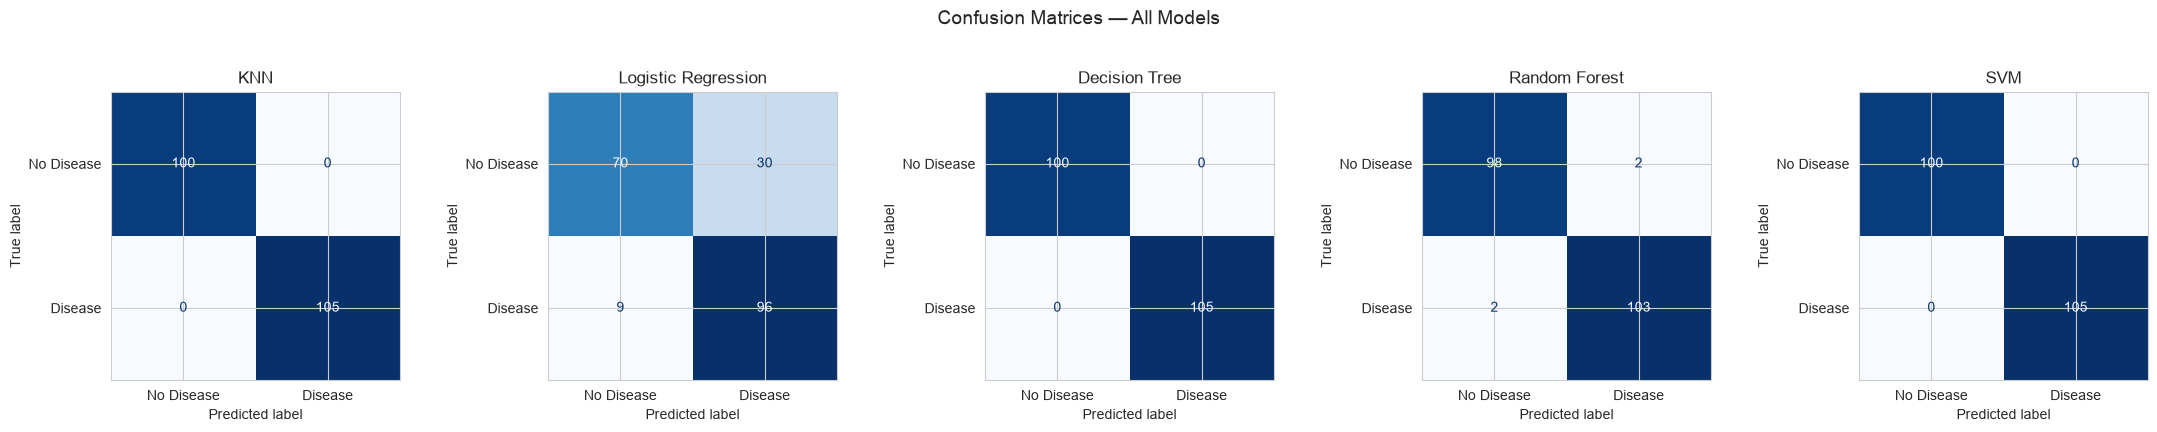

In [12]:
# ---- Confusion Matrices ----
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, cm) in zip(axes, cm_dict.items()):
    ConfusionMatrixDisplay(cm, display_labels=["No Disease", "Disease"]).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(name)
plt.suptitle("Confusion Matrices — All Models", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

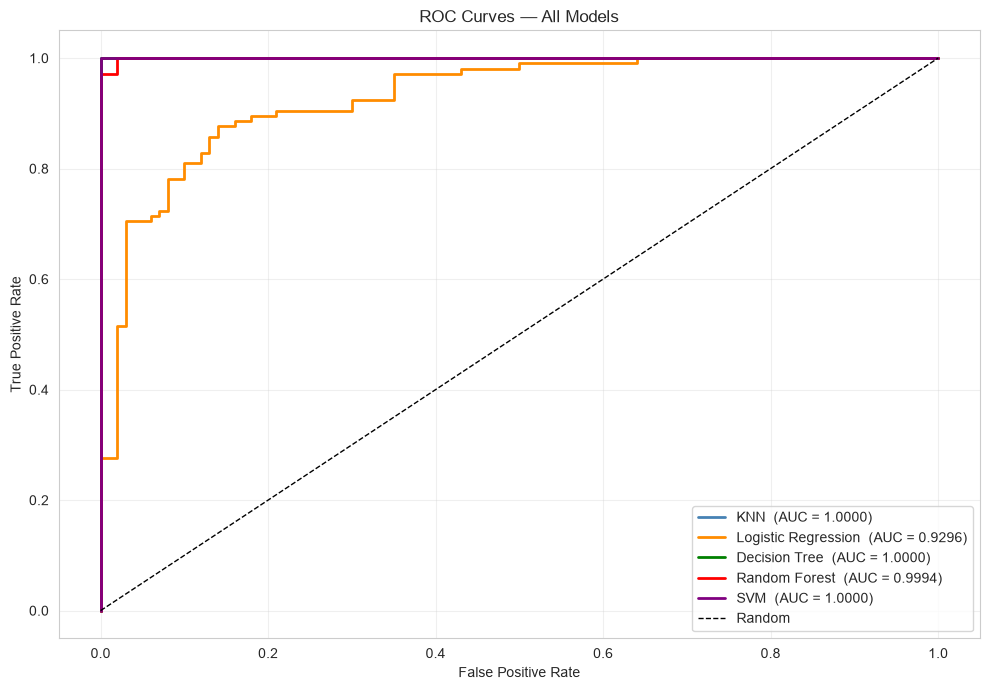

In [13]:
# ---- ROC Curves ----
plt.figure(figsize=(10, 7))
colors = ["steelblue", "darkorange", "green", "red", "purple"]

for (name, (fpr, tpr, roc_auc)), color in zip(roc_curves.items(), colors):
    plt.plot(fpr, tpr, lw=2, color=color,
             label=f"{name}  (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

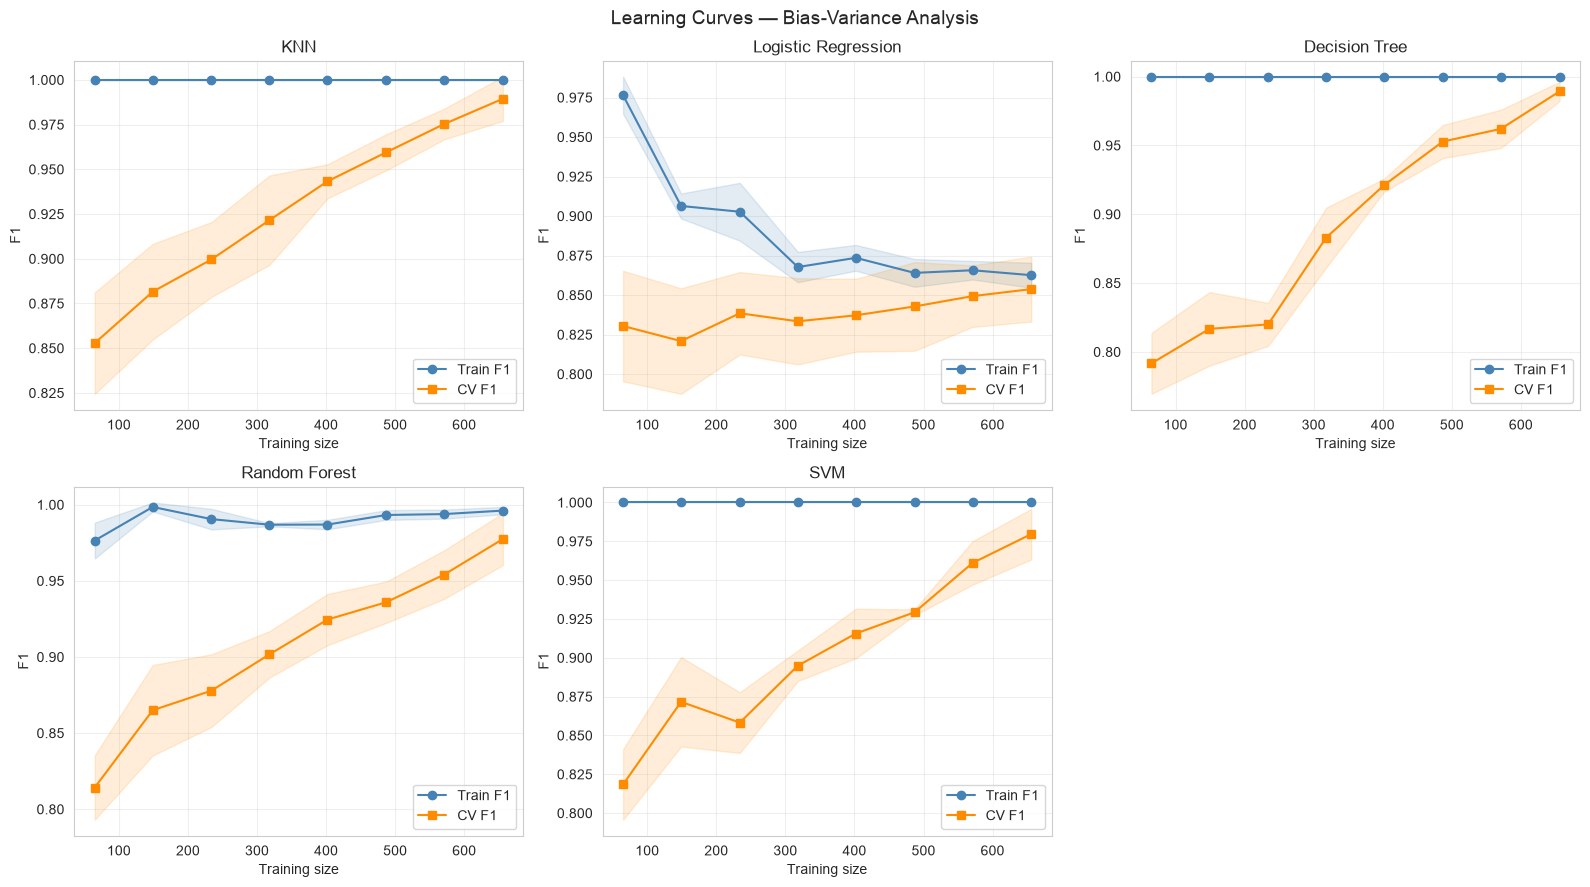

In [14]:
# ---- Learning curves for the best model (typically RF) ----
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for ax, (name, (model, X_t, _)) in zip(axes, models.items()):
    # Use the training data that matches the model's needs
    X_tr = X_train_scaled if name in ["KNN", "Logistic Regression", "SVM"] else X_train

    train_sizes, train_scores, val_scores = learning_curve(
        model, X_tr, y_train,
        cv=5, scoring="f1",
        train_sizes=np.linspace(0.1, 1.0, 8),
        n_jobs=-1
    )

    ax.plot(train_sizes, train_scores.mean(1), "o-",
            color="steelblue", label="Train F1")
    ax.fill_between(train_sizes,
                    train_scores.mean(1) - train_scores.std(1),
                    train_scores.mean(1) + train_scores.std(1),
                    alpha=0.15, color="steelblue")

    ax.plot(train_sizes, val_scores.mean(1), "s-",
            color="darkorange", label="CV F1")
    ax.fill_between(train_sizes,
                    val_scores.mean(1) - val_scores.std(1),
                    val_scores.mean(1) + val_scores.std(1),
                    alpha=0.15, color="darkorange")

    ax.set_title(f"{name}")
    ax.set_xlabel("Training size")
    ax.set_ylabel("F1")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

axes.ravel()[-1].axis("off")
plt.suptitle("Learning Curves — Bias-Variance Analysis", fontsize=14)
plt.tight_layout()
plt.show()

## Task 7: Comprehensive Model Comparison
- Create comparison table of all models' performance metrics
- Visualize performance comparison using bar charts
- Identify the best performing model based on multiple criteria
- Discuss trade-offs between different evaluation metrics


FINAL COMPARISON TABLE
              Model  Accuracy  Precision  Recall     F1    AUC
                KNN    1.0000     1.0000  1.0000 1.0000 1.0000
      Decision Tree    1.0000     1.0000  1.0000 1.0000 1.0000
                SVM    1.0000     1.0000  1.0000 1.0000 1.0000
      Random Forest    0.9805     0.9810  0.9810 0.9810 0.9994
Logistic Regression    0.8098     0.7619  0.9143 0.8312 0.9296


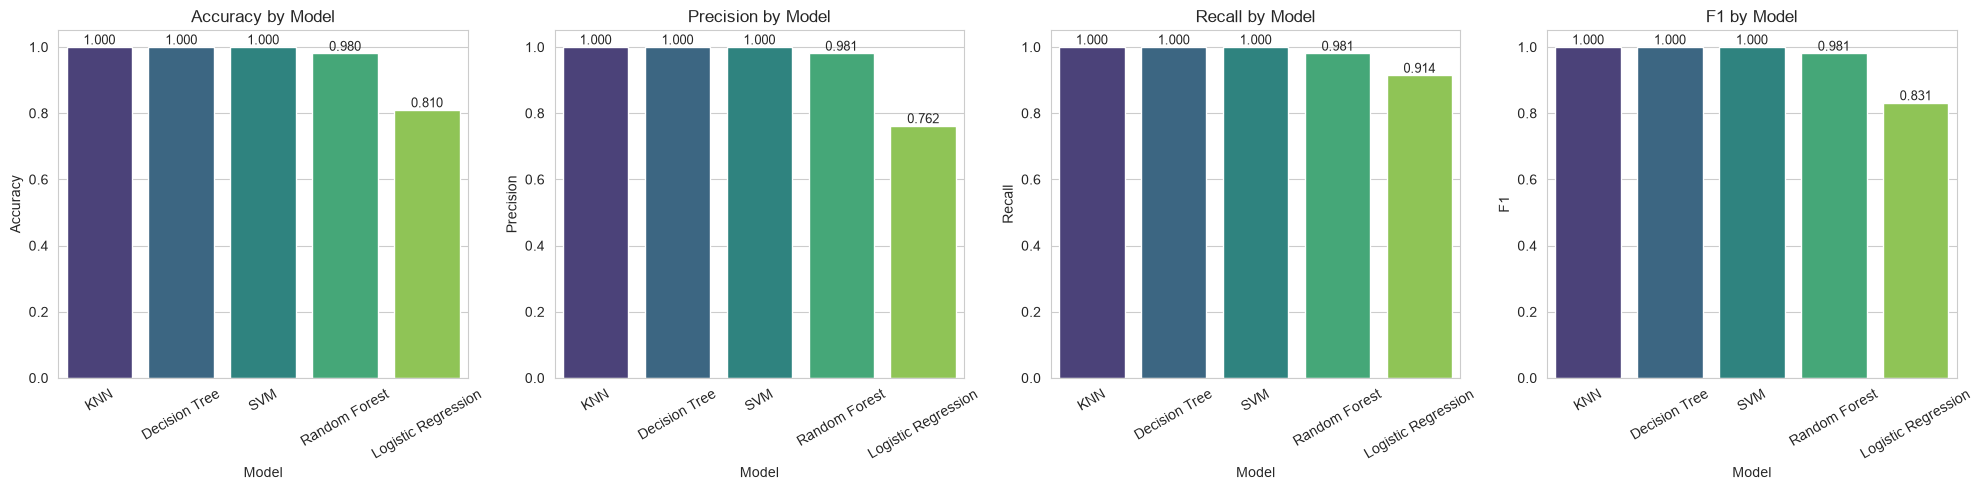

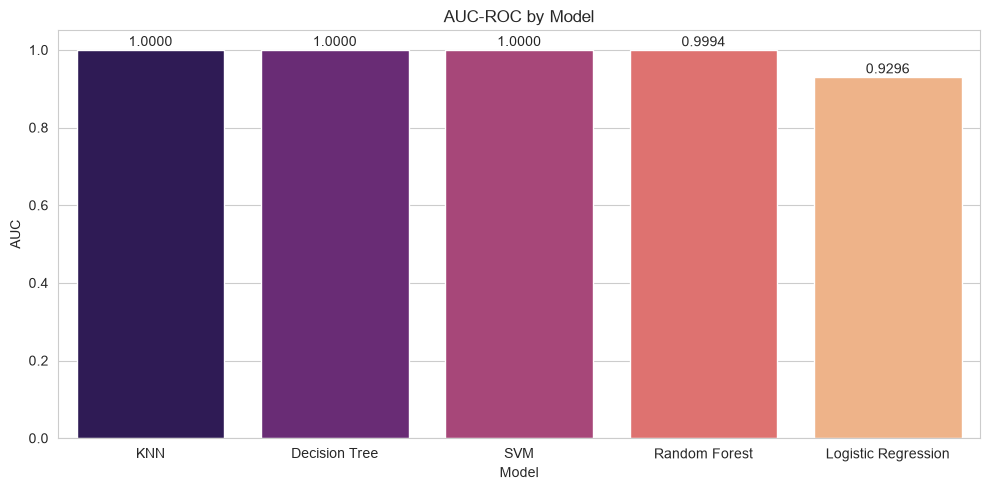


🏆 Best model by F1: KNN
   F1 = 1.0000, AUC = 1.0000


In [15]:
# Your code here
# ============================================================
# TASK 7 — MODEL COMPARISON
# ============================================================
# ---- Add AUC to metrics table ----
metrics_df["AUC"] = [roc_curves[m][2] for m in metrics_df["Model"]]

# Round for display
metrics_display = metrics_df.copy()
for col in ["Accuracy", "Precision", "Recall", "F1", "AUC"]:
    metrics_display[col] = metrics_display[col].round(4)

print("\n" + "=" * 75)
print("FINAL COMPARISON TABLE")
print("=" * 75)
print(metrics_display.to_string(index=False))

# ---- Bar charts ----
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, metric in zip(axes, ["Accuracy", "Precision", "Recall", "F1"]):
    sns.barplot(data=metrics_df, x="Model", y=metric, ax=ax, palette="viridis")
    ax.set_title(f"{metric} by Model")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=30)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}",
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

# ---- Overall AUC comparison ----
plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_df, x="Model", y="AUC", palette="magma")
plt.title("AUC-ROC by Model")
plt.ylim(0, 1.05)
for i, v in enumerate(metrics_df["AUC"]):
    plt.text(i, v + 0.01, f"{v:.4f}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

# ---- Print winner ----
best_model_name = metrics_df.iloc[0]["Model"]
print(f"\n🏆 Best model by F1: {best_model_name}")
print(f"   F1 = {metrics_df.iloc[0]['F1']:.4f}, "
      f"AUC = {metrics_df.iloc[0]['AUC']:.4f}")

In [16]:
# If we prioritize recall:
rf_recall = RandomForestClassifier(
    n_estimators=200, max_depth=6,
    class_weight={0: 1, 1: 3},   # penalize missed disease 3x
    random_state=42
)
rf_recall.fit(X_train, y_train)
y_pred_recall = rf_recall.predict(X_test)

print(f"Recall-focused RF:  Recall={recall_score(y_test, y_pred_recall):.4f}, "
      f"Precision={precision_score(y_test, y_pred_recall):.4f}")

Recall-focused RF:  Recall=1.0000, Precision=0.8203


In [17]:
final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight={0: 1, 1: 2},   # slight favor for disease detection
    random_state=42
)
final_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{0: 1, 1: 2}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1